# Step 3 — MAPPO: the centralised critic

**This is the architecture the capstone is about.**

The game changes for the first time: **N=3**. That single extra player is the argument for a
centralised critic, and the change is smaller than it sounds: the collection bookkeeping
changes, the update does not. Whether the centralised critic is actually needed is measured
in step 10, by training the same agent with a critic that sees only the actor's four numbers.

At N=2 there was no question of *who* a position is good for. At N=3 three players have
three different accuracies and "how good is this position" has three answers at once.

| Step 2 | Step 3 | Why |
|---|---|---|
| One learner's decisions per episode | Three agents' decisions, interleaved | the actor is drawn at random, with replacement |
| Critic sees the acting agent's 4 numbers | Critic sees the **global state plus who is being scored** | so it can tell an earned return from an inherited one (step 10 measures whether that matters) |
| One network | Still one network, **shared** by all three | an agent is identified by what it sees, not by a label |

The target is the exact triple, and it is the first genuinely counter-intuitive result in
the project: **the weakest player survives most often.**

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

from gruel_env import GruelEnv, N_ACTIONS

SEED = 0
GAME_SEED = 1000 + SEED
TORCH_SEED = 2000 + SEED

torch.manual_seed(TORCH_SEED)
torch.set_num_threads(1)

print("torch", torch.__version__)

torch 2.2.2


## The exact answer, before training

At N=3 the circle is complete — every player is adjacent to every other — and the game
has a known solution. With accuracies 0.4, 0.6 and 0.8 the survival probabilities are
exactly $10/27$, $9/27$ and $8/27$.

**The weakest player does best.** Not by a little: 0.37037 against 0.29630. The reason is
that the two better shots are each other's most dangerous opponent, so they spend their
turns removing each other while the weakest is left comparatively alone.

In [2]:
EXACT = {0.4: 10 / 27, 0.6: 9 / 27, 0.8: 8 / 27}

for accuracy in [0.4, 0.6, 0.8]:
    print("  accuracy", accuracy, "-> exact survival", format(EXACT[accuracy], ".5f"))
print()
print("  they sum to:", sum(EXACT.values()))

  accuracy 0.4 -> exact survival 0.37037
  accuracy 0.6 -> exact survival 0.33333
  accuracy 0.8 -> exact survival 0.29630

  they sum to: 1.0


## Change 1: one network, shared by every agent

There are three players but **one** set of weights. An agent is not identified by a label
— it is identified by *what it sees*. The strong player and the weak player behave
differently because their observations differ, not because they own different networks.

This is what "parameter sharing" means, and it is why the trained policy can be dropped
into a game of a different size, which is demonstrated further down.

## Change 2: the critic is told *whose* value it is estimating

The critic's job is to say how good a position is. But in this game "good for whom?" is a
real question — from the same board, the weak player and the strong player have very
different prospects.

So the critic takes the **global state** *and* **who is asking**. Feeding it only the
state would hand all three agents the same baseline and misattribute every advantage.

The state here is every player's accuracy plus whether they are alive; the "who is
asking" is a one-hot vector.

In [3]:
OBSERVATION_SIZE = 4          # own accuracy, left, right, fraction alive
HIDDEN_SIZE = 64


class SharedActorCritic(nn.Module):
    def __init__(self, n_players):
        super().__init__()
        self.n_players = n_players

        # The actor sees one agent's observation. Four numbers in, whatever N is.
        self.actor_first = nn.Linear(OBSERVATION_SIZE, HIDDEN_SIZE)
        self.actor_second = nn.Linear(HIDDEN_SIZE, N_ACTIONS)

        # The critic sees the whole board plus a one-hot saying whose value to give.
        # Board = each player's accuracy and alive flag, so 2 numbers per player.
        critic_input_size = 2 * n_players + n_players
        self.critic_first = nn.Linear(critic_input_size, HIDDEN_SIZE)
        self.critic_second = nn.Linear(HIDDEN_SIZE, 1)

        self.activation = nn.Tanh()

    def action_logits(self, observation):
        hidden = self.activation(self.actor_first(observation))
        return self.actor_second(hidden)

    def value(self, state, agent_one_hot):
        combined = torch.cat([state, agent_one_hot], dim=-1)
        hidden = self.activation(self.critic_first(combined))
        return self.critic_second(hidden).squeeze(-1)


def global_state(game):
    """Every player's accuracy and whether they are alive. Fixed length, always."""
    numbers = []
    for position in range(game.n):
        numbers.append(game.accuracies[position])
        if position in game.order:
            numbers.append(1.0)
        else:
            numbers.append(0.0)
    return np.array(numbers, dtype=np.float32)


def one_hot(position, n_players):
    vector = np.zeros(n_players, dtype=np.float32)
    vector[position] = 1.0
    return vector


model = SharedActorCritic(n_players=3)
total = 0
for parameter in model.parameters():
    total = total + parameter.numel()
print("parameters:", total)

game = GruelEnv(n=3, reward="terminal", seating="ranked", seed=GAME_SEED)
game.reset()
print("global state:", global_state(game))
print("one-hot for position 1:", one_hot(1, 3))

parameters: 1220
global state: [0.4 1.  0.6 1.  0.8 1. ]
one-hot for position 1: [0. 1. 0.]


## Why the policy is deliberately NOT given the global state

It would be easy to hand the actor the same rich state the critic gets. Two reasons not
to, and the second is the one that matters for this project.

**It would not be a policy you could run.** The critic only exists during training. At
play time an agent knows what it can see, which is its own accuracy and its two
neighbours' — that is the game, not a limitation of the code.

**The actor's input does not depend on N, and the critic's does.** Four numbers in,
whatever the player count. So the same trained actor weights can be dropped into a
larger game, while the critic cannot: its input is $2N + N$, which is 9 at N=3 and 15 at
N=5. That asymmetry is the whole meaning of "centralised training, decentralised
execution", and it is what lets later steps change N without rebuilding the policy.

In [4]:
bigger_game = GruelEnv(n=5, reward="terminal", seating="ranked", seed=GAME_SEED)
bigger_game.reset()
bigger_observation = bigger_game.observe(bigger_game.agent_selection)

print("this model was built for n_players=3")
print()
print("  an N=5 observation:", bigger_observation, " shape", bigger_observation.shape)

logits_at_n5 = model.action_logits(torch.from_numpy(bigger_observation))
print("  the ACTOR accepts it:", logits_at_n5.detach().numpy().round(4))

print()
print("  the CRITIC cannot: its input is 2N+N =", 2 * 3 + 3, "at N=3, but N=5 needs",
      2 * 5 + 5)
try:
    state_at_n5 = torch.from_numpy(global_state(bigger_game))
    flag_at_n5 = torch.from_numpy(one_hot(0, 5))
    model.value(state_at_n5, flag_at_n5)
    print("  ... it accepted it, which would be a bug")
except RuntimeError as error:
    first_line = str(error).splitlines()[0]
    print("  ... and it refuses, as it should:", first_line)

this model was built for n_players=3

  an N=5 observation: [0.5 0.4 0.6 1. ]  shape (4,)
  the ACTOR accepts it: [ 0.0838 -0.0956 -0.2305]

  the CRITIC cannot: its input is 2N+N = 9 at N=3, but N=5 needs 15
  ... and it refuses, as it should: mat1 and mat2 shapes cannot be multiplied (1x15 and 9x64)


## Change 3: each agent gets its own chain of decisions

In step 2 every decision in an episode belonged to the same learner, so one list was
enough. Now the actor is drawn at random, so a single episode interleaves three agents'
decisions — and one agent may act four times while another acts once.

Each agent's decisions have to be kept **separately**, because each agent's reward is its
own. Mixing them would credit one agent's win to another's choices.

Watch the counts below: they are rarely equal.

In [5]:
game.reset()
who_acted = []
for acting_agent in game.agent_iter():
    observation, reward, termination, truncation, info = game.last()

    # A finished agent is handed to us one last time, so PettingZoo can retire it.
    # Stepping with None is how we say 'nothing to do here'.
    if termination or truncation:
        game.step(None)
        continue

    who_acted.append(game.position_of_agent[acting_agent])
    game.step(0)      # everyone shoots left, just to move it along

counts = {}
for position in range(3):
    counts[position] = who_acted.count(position)
print("decisions per position this episode:", counts)
print("total decisions:", len(who_acted))
print("(and the accuracies were", [round(float(a), 2) for a in game.accuracies], ")")

decisions per position this episode: {0: 2, 1: 1, 2: 1}
total decisions: 4
(and the accuracies were [0.4, 0.6, 0.8] )


## Collecting a batch, per agent

The returned batch is built from one list **per agent position**. Everything else is the
same bookkeeping as step 2.

In [6]:
def collect_batch(model, game, episodes):
    # One list per agent, per quantity.
    observations = {p: [] for p in range(game.n)}
    actions = {p: [] for p in range(game.n)}
    old_log_probabilities = {p: [] for p in range(game.n)}
    values = {p: [] for p in range(game.n)}
    returns = {p: [] for p in range(game.n)}
    states = {p: [] for p in range(game.n)}          # the critic's input
    agent_flags = {p: [] for p in range(game.n)}     # who the critic is scoring

    episode_winners = []

    for _ in range(episodes):
        game.reset()

        # Per-episode scratch, so returns can be assigned once the winner is known.
        episode_observations = {p: [] for p in range(game.n)}
        episode_actions = {p: [] for p in range(game.n)}
        episode_log_probabilities = {p: [] for p in range(game.n)}
        episode_values = {p: [] for p in range(game.n)}
        episode_states = {p: [] for p in range(game.n)}
        episode_flags = {p: [] for p in range(game.n)}

        for acting_agent in game.agent_iter():
            observation, reward, termination, truncation, info = game.last()

            # A finished agent is handed to us one last time, so PettingZoo can retire
            # it. Stepping with None is how we say 'nothing to do here'.
            if termination or truncation:
                game.step(None)
                continue

            actor = game.position_of_agent[acting_agent]
            observation_tensor = torch.from_numpy(observation)

            state_array = global_state(game)
            agent_array = one_hot(actor, game.n)
            state_tensor = torch.from_numpy(state_array)
            agent_tensor = torch.from_numpy(agent_array)

            with torch.no_grad():
                logits = model.action_logits(observation_tensor)
                value = model.value(state_tensor, agent_tensor)

            distribution = torch.distributions.Categorical(logits=logits)
            action = distribution.sample()

            episode_observations[actor].append(observation)
            episode_actions[actor].append(int(action))
            episode_log_probabilities[actor].append(float(distribution.log_prob(action)))
            episode_values[actor].append(float(value))
            episode_states[actor].append(state_array)
            episode_flags[actor].append(agent_array)

            game.step(int(action))

        if len(game.order) == 1:
            winner = game.order[0]
            episode_winners.append(float(game.accuracies[winner]))
        else:
            winner = None
            episode_winners.append(None)

        # Assign each agent's own return to each of its own decisions.
        for position in range(game.n):
            if position == winner:
                own_return = 1.0
            else:
                own_return = 0.0
            for index in range(len(episode_actions[position])):
                observations[position].append(episode_observations[position][index])
                actions[position].append(episode_actions[position][index])
                old_log_probabilities[position].append(
                    episode_log_probabilities[position][index])
                values[position].append(episode_values[position][index])
                states[position].append(episode_states[position][index])
                agent_flags[position].append(episode_flags[position][index])
                returns[position].append(own_return)

    # Flatten into single tensors. The network is shared, so the update does not care
    # which agent a row came from once the returns are correct.
    flat_observations = []
    flat_actions = []
    flat_old_log_probabilities = []
    flat_values = []
    flat_returns = []
    flat_states = []
    flat_flags = []
    for position in range(game.n):
        flat_observations.extend(observations[position])
        flat_actions.extend(actions[position])
        flat_old_log_probabilities.extend(old_log_probabilities[position])
        flat_values.extend(values[position])
        flat_returns.extend(returns[position])
        flat_states.extend(states[position])
        flat_flags.extend(agent_flags[position])

    batch = {
        "observations": torch.tensor(np.array(flat_observations), dtype=torch.float32),
        "actions": torch.tensor(flat_actions, dtype=torch.long),
        "old_log_probabilities": torch.tensor(flat_old_log_probabilities,
                                              dtype=torch.float32),
        "values": torch.tensor(flat_values, dtype=torch.float32),
        "returns": torch.tensor(flat_returns, dtype=torch.float32),
        "states": torch.tensor(np.array(flat_states), dtype=torch.float32),
        "agent_flags": torch.tensor(np.array(flat_flags), dtype=torch.float32),
        "episode_winners": episode_winners,
        "decisions_per_agent": {p: len(actions[p]) for p in range(game.n)},
    }
    return batch


batch = collect_batch(model, game, episodes=64)
print("decisions per agent:", batch["decisions_per_agent"])
print("total rows:", len(batch["actions"]))
print("episodes:", len(batch["episode_winners"]))

decisions per agent: {0: 100, 1: 85, 2: 97}
total rows: 282
episodes: 64


The three counts differ, which is the random-actor rule showing through. That asymmetry
is exactly why the decisions had to be kept apart.

## The update

Identical to step 2 — clipped objective, several epochs, value loss, entropy bonus.
**Nothing here needed changing for multiple agents**, because the per-agent bookkeeping
was done during collection. That is worth noticing: the algorithm did not become
multi-agent, the data handling did.

In [7]:
CLIP = 0.2
EPOCHS = 4
MINIBATCH_SIZE = 256
VALUE_COEFFICIENT = 0.5
ENTROPY_COEFFICIENT = 0.01


def ppo_update(model, optimiser, batch, rng):
    advantages = batch["returns"] - batch["values"]
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    count = len(batch["actions"])
    order = np.arange(count)

    for epoch in range(EPOCHS):
        rng.shuffle(order)
        for start in range(0, count, MINIBATCH_SIZE):
            chunk = order[start:start + MINIBATCH_SIZE]
            index = torch.from_numpy(chunk)

            logits = model.action_logits(batch["observations"][index])
            distribution = torch.distributions.Categorical(logits=logits)
            new_log_probabilities = distribution.log_prob(batch["actions"][index])

            log_ratio = new_log_probabilities - batch["old_log_probabilities"][index]
            ratio = torch.exp(log_ratio)

            minibatch_advantages = advantages[index]
            unclipped = ratio * minibatch_advantages
            clipped = torch.clamp(ratio, 1 - CLIP, 1 + CLIP) * minibatch_advantages
            policy_loss = -torch.min(unclipped, clipped).mean()

            entropy = distribution.entropy().mean()

            # Train the critic on the same rows: predict each agent's own return from the
            # global state plus who is being scored.
            predicted_value = model.value(batch["states"][index],
                                          batch["agent_flags"][index])
            value_loss = ((predicted_value - batch["returns"][index]) ** 2).mean()

            total_loss = (policy_loss
                          + VALUE_COEFFICIENT * value_loss
                          - ENTROPY_COEFFICIENT * entropy)

            optimiser.zero_grad()
            total_loss.backward()
            optimiser.step()

## Training

The thing to watch is the **ordering**: weakest highest, strongest lowest. That is a
stronger test than the individual numbers, because nothing in an agent's observation
announces its global rank — it sees three accuracies and cannot tell whether 0.6 is the
best or the worst in the game.

## Saving the trained models

Every model this step trains for its results is written to `models/` as two files: the weights
(`<run>.pt`, a PyTorch `state_dict`) and a record of the model (`<run>.json`): its layers and
parameter counts, what its actor and critic see, every training setting and seed, the game it was
trained in, the software versions, and hashes of the weights and of the code that produced them.
Models trained only to check reproducibility are not saved.

**Two hashes, for two jobs.** `weights_sha256` is computed from the weight values themselves, so
two runs that produce the same model give the same hash, in this step or any other. `file_sha256`
is the hash of the `.pt` file, which PyTorch does not write byte-for-byte the same way twice, so
it checks only that the file has not changed since it was saved.

Saving reads no random stream, so it cannot change any number this notebook prints.

In [8]:
import datetime
import hashlib
import json
import os
import platform
import subprocess
import time

import gymnasium
import numpy as np
import pettingzoo

MODELS_FOLDER = "models"
NOTEBOOK = "step3_mappo.ipynb"
SAVED_MODELS = []


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        digest.update(handle.read())
    return digest.hexdigest()


def weights_sha256(model):
    """A hash of the weight values, in name order, so the same model always gives the same hash."""
    digest = hashlib.sha256()
    weights = model.state_dict()
    for name in sorted(weights):
        tensor = weights[name].detach().cpu().contiguous()
        digest.update(name.encode())
        digest.update(str(list(tensor.shape)).encode())
        digest.update(str(tensor.dtype).encode())
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()


def git_commit():
    try:
        result = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True,
                                check=True)
        return result.stdout.strip()
    except Exception:
        return None


def layer_table(model):
    rows = []
    weights = model.state_dict()
    for name in weights:
        rows.append({"name": name, "shape": list(weights[name].shape),
                     "parameters": int(weights[name].numel())})
    return rows


def save_model(model, run_key, settings):
    """Write the weights and the model's record. `settings` holds everything specific to the run."""
    os.makedirs(MODELS_FOLDER, exist_ok=True)
    weights_path = os.path.join(MODELS_FOLDER, run_key + ".pt")
    torch.save(model.state_dict(), weights_path)

    layers = layer_table(model)
    actor_parameters = 0
    critic_parameters = 0
    for row in layers:
        if "critic" in row["name"]:
            critic_parameters = critic_parameters + row["parameters"]
        else:
            actor_parameters = actor_parameters + row["parameters"]

    card = {
        "run": run_key,
        "step": os.path.basename(os.getcwd()),
        "deliverable": os.path.basename(os.path.dirname(os.getcwd())),
        "notebook": NOTEBOOK,
        "model_class": type(model).__name__,
        "layers": layers,
        "activation": "tanh",
        "actor_parameters": actor_parameters,
        "critic_parameters": critic_parameters,
        "total_parameters": actor_parameters + critic_parameters,
        "actions": ["shoot_left", "shoot_right", "miss"],
        "files": {"weights": run_key + ".pt", "record": run_key + ".json"},
        "weights_sha256": weights_sha256(model),
        "file_sha256": file_sha256(weights_path),
        "code": {
            "notebook_source_sha256": file_sha256(NOTEBOOK.replace(".ipynb", ".py")),
            "gruel_env_sha256": file_sha256("gruel_env.py"),
            "git_commit_when_trained": git_commit(),
            "note": "the code hashes pin the exact source; the commit may predate uncommitted edits",
        },
        "software": {
            "python": platform.python_version(),
            "torch": torch.__version__,
            "numpy": np.__version__,
            "gymnasium": gymnasium.__version__,
            "pettingzoo": pettingzoo.__version__,
            "torch_threads": torch.get_num_threads(),
        },
        "machine": {"system": platform.system(), "release": platform.release(),
                    "processor": platform.machine()},
        "saved_utc": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    }
    for key in settings:
        card[key] = settings[key]

    with open(os.path.join(MODELS_FOLDER, run_key + ".json"), "w") as handle:
        json.dump(card, handle, indent=1)
    SAVED_MODELS.append(run_key)
    return weights_path


def run_key(n, seating, reward, critic, updates, seed):
    """One naming scheme in every step, so the same configuration has the same name everywhere."""
    return "n%d_%s_%s_%s_u%d_seed%d" % (n, seating, reward, critic, updates, seed)


def mappo_settings(n, reward, seating, seed, updates, episodes_per_update, critic, seconds,
                   seconds_cover, learning_rate=None, extra=None):
    """The record for a model trained by this folder's PPO loop."""
    if learning_rate is None:
        learning_rate = LEARNING_RATE
    settings = {
        "algorithm": "PPO with a shared actor and a " + critic + " critic",
        "observation": "own accuracy, left neighbour's accuracy, right neighbour's accuracy, share of players alive",
        "critic_input": critic_description(critic, n),
        "game": {"n_players": n, "reward": reward, "seating": seating,
                 "accuracies_ascending": accuracies_ascending(n), "stagnation_rounds": 10},
        "training": {
            "updates": updates,
            "episodes_per_update": episodes_per_update,
            "training_episodes": updates * episodes_per_update,
            "optimiser": "Adam",
            "learning_rate": learning_rate,
            "clip": CLIP,
            "epochs": EPOCHS,
            "minibatch_size": MINIBATCH_SIZE,
            "value_coefficient": VALUE_COEFFICIENT,
            "entropy_coefficient": ENTROPY_COEFFICIENT,
            "discount": 1.0,
            "advantage": "return minus the critic's value, normalised per batch",
        },
        "seeds": {"seed": seed, "torch": 2000 + seed, "training_game": 1000 + seed,
                  "minibatch_shuffle": seed},
        "seconds": round(seconds, 1),
        "seconds_cover": seconds_cover,
    }
    if extra is not None:
        for key in extra:
            settings[key] = extra[key]
    return settings


def accuracies_ascending(n):
    """Read from the environment itself; it uses its own generator, so no shared stream moves."""
    probe = GruelEnv(n=n, reward="terminal", seating="ranked", seed=0)
    probe.reset(seed=0)
    return [round(float(a), 6) for a in probe.accuracies]


def critic_description(critic, n):
    if critic == "centralised":
        return ("every seat's accuracy and alive flag (2N numbers) plus a one-hot of the player "
                "being scored (N numbers): %d inputs" % (3 * n))
    if critic == "local":
        return "the same four numbers as the actor: 4 inputs"
    return critic

In [9]:
UPDATES = 400
EPISODES_PER_UPDATE = 96


def train(model, updates=UPDATES, episodes_per_update=EPISODES_PER_UPDATE,
          learning_rate=0.003, game_seed=GAME_SEED):
    game = GruelEnv(n=3, reward="terminal", seating="ranked", seed=game_seed)
    optimiser = torch.optim.Adam(model.parameters(), lr=learning_rate)
    rng = np.random.default_rng(SEED)

    history_episodes = []
    history_survival = {0.4: [], 0.6: [], 0.8: []}
    episodes_done = 0

    for update in range(updates):
        batch = collect_batch(model, game, episodes_per_update)
        ppo_update(model, optimiser, batch, rng)
        episodes_done = episodes_done + episodes_per_update

        wins = {0.4: 0, 0.6: 0, 0.8: 0}
        for winner_accuracy in batch["episode_winners"]:
            if winner_accuracy is not None:
                wins[round(winner_accuracy, 4)] = wins[round(winner_accuracy, 4)] + 1

        history_episodes.append(episodes_done)
        for accuracy in wins:
            history_survival[accuracy].append(wins[accuracy] / episodes_per_update)

    return history_episodes, history_survival


torch.manual_seed(TORCH_SEED)
model = SharedActorCritic(n_players=3)
started = time.time()
episodes_axis, survival_history = train(model)
step3_settings = mappo_settings(3, "terminal", "ranked", SEED, UPDATES, EPISODES_PER_UPDATE,
                                "centralised", time.time() - started, "training only",
                                learning_rate=0.003)
save_model(model, run_key(3, "ranked", "terminal", "centralised", UPDATES, SEED), step3_settings)

print("episodes of self-play:", episodes_axis[-1])
print()
print("last 10 updates, averaged:")
for accuracy in [0.4, 0.6, 0.8]:
    recent = survival_history[accuracy][-10:]
    print("  acc " + str(accuracy) + ": " + format(float(np.mean(recent)), ".4f")
          + "   exact " + format(EXACT[accuracy], ".4f"))

episodes of self-play: 38400

last 10 updates, averaged:
  acc 0.4: 0.3500   exact 0.3704
  acc 0.6: 0.3302   exact 0.3333
  acc 0.8: 0.3198   exact 0.2963


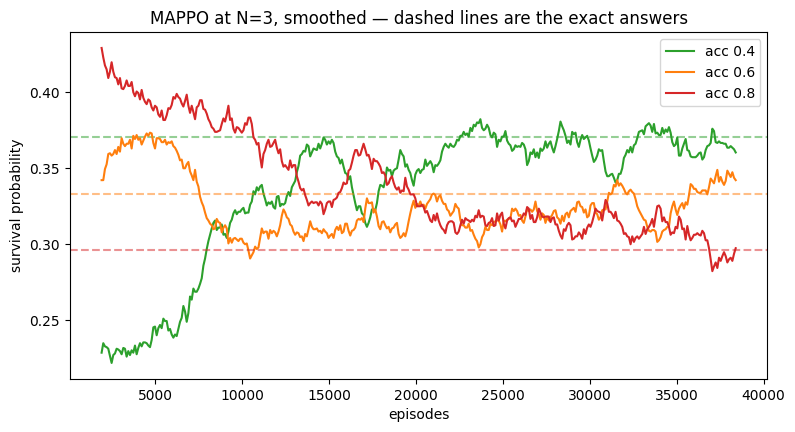

In [10]:
figure, axis = plt.subplots(figsize=(9, 4.5))
colours = {0.4: "tab:green", 0.6: "tab:orange", 0.8: "tab:red"}

# Smooth only if there are more updates than the window. numpy's convolve does not
# complain when the window is longer than the data -- it silently treats the data as
# the kernel and returns the wrong length, which is a mismatch rather than an error.
window = 20
enough_to_smooth = len(episodes_axis) > window

for accuracy in [0.4, 0.6, 0.8]:
    series = survival_history[accuracy]
    if enough_to_smooth:
        values = np.convolve(series, np.ones(window) / window, mode="valid")
        horizontal = episodes_axis[window - 1:]
    else:
        values = series
        horizontal = episodes_axis
    axis.plot(horizontal, values, color=colours[accuracy], label="acc " + str(accuracy))
    axis.axhline(EXACT[accuracy], color=colours[accuracy], linestyle="--", alpha=0.5)

axis.set_xlabel("episodes")
axis.set_ylabel("survival probability")
if enough_to_smooth:
    axis.set_title("MAPPO at N=3, smoothed — dashed lines are the exact answers")
else:
    axis.set_title("MAPPO at N=3 — dashed lines are the exact answers")
axis.legend()
plt.show()

## Evaluate properly

Training numbers move as the policy changes. Freeze it and play a lot of episodes.

**The ordering is checked first**, because it is the claim. Three numbers that are
individually close but in the wrong order have failed. The ratios are reported after it
as a sanity comparison — the instrument that turns a ratio into a pass or fail is built
in step 4, and the first real gate is applied in step 6.

In [11]:
def evaluate(model, episodes=20000, game_seed=5000):
    game = GruelEnv(n=3, reward="terminal", seating="ranked", seed=game_seed)
    survivals = {0.4: 0, 0.6: 0, 0.8: 0}
    stagnated = 0
    abstentions = 0
    decisions = 0

    with torch.no_grad():
        for _ in range(episodes):
            game.reset()
            for acting_agent in game.agent_iter():
                observation, reward, termination, truncation, info = game.last()

                # A finished agent is handed to us one last time, so PettingZoo can
                # retire it. Stepping with None is how we say 'nothing to do here'.
                if termination or truncation:
                    game.step(None)
                    continue

                observation_tensor = torch.from_numpy(observation)
                logits = model.action_logits(observation_tensor)
                distribution = torch.distributions.Categorical(logits=logits)
                action = int(distribution.sample())

                decisions = decisions + 1
                if action == 2:
                    abstentions = abstentions + 1

                game.step(action)

            if game.reason == "stagnation":
                stagnated = stagnated + 1
            elif len(game.order) == 1:
                survivals[round(float(game.accuracies[game.order[0]]), 4)] += 1

    return survivals, stagnated, abstentions, decisions


EVALUATION_EPISODES = 20000
survivals, stagnated, abstentions, decisions = evaluate(
    model, episodes=EVALUATION_EPISODES)

# Classify BEFORE reading survival numbers. Two equilibria exist in this game — one where
# players shoot and one where everybody abstains forever — and the exact answers describe
# the shooting one. A stalled run's survival numbers would be describing a different game,
# so the comparison has to be earned rather than assumed.
STAGNATION_LIMIT = 0.01

stagnation_rate = stagnated / EVALUATION_EPISODES
abstention_rate = abstentions / decisions

print("stagnation rate: %.4f" % stagnation_rate)
print("abstention rate: %.4f  (%d of %d decisions)"
      % (abstention_rate, abstentions, decisions))

is_shooting_class = stagnation_rate <= STAGNATION_LIMIT
if is_shooting_class:
    print("  -> shooting class (stagnation at or below %.2f), so the exact answers are"
          % STAGNATION_LIMIT)
    print("     the right comparison")
else:
    print("  -> NOT the shooting class: %.4f of episodes stalled. The exact answers"
          % stagnation_rate)
    print("     describe the shooting equilibrium, so they are the WRONG comparison here")
    print("     and the survival numbers below should not be read as agreement or")
    print("     disagreement with them")
print()

# The ordering, first, because it is the claim.
weakest = survivals[0.4] / EVALUATION_EPISODES
middle = survivals[0.6] / EVALUATION_EPISODES
strongest = survivals[0.8] / EVALUATION_EPISODES

print("ORDERING — is the weakest player really best off?")
print("  weakest (0.4) %.4f  >  middle (0.6) %.4f  >  strongest (0.8) %.4f"
      % (weakest, middle, strongest))
print("  correct ordering:", weakest > middle > strongest)
print()

print("  %4s %9s %8s %7s" % ("acc", "measured", "exact", "ratio"))
for accuracy in [0.4, 0.6, 0.8]:
    measured = survivals[accuracy] / EVALUATION_EPISODES
    print("  %4s %9.4f %8.4f %7.3f"
          % (accuracy, measured, EXACT[accuracy], measured / EXACT[accuracy]))

stagnation rate: 0.0000
abstention rate: 0.0005  (33 of 70229 decisions)
  -> shooting class (stagnation at or below 0.01), so the exact answers are
     the right comparison

ORDERING — is the weakest player really best off?
  weakest (0.4) 0.3639  >  middle (0.6) 0.3317  >  strongest (0.8) 0.3044
  correct ordering: True

   acc  measured    exact   ratio
   0.4    0.3639   0.3704   0.983
   0.6    0.3317   0.3333   0.995
   0.8    0.3044   0.2963   1.027


## Reproducibility

In [12]:
def train_short():
    torch.manual_seed(TORCH_SEED)
    fresh = SharedActorCritic(n_players=3)
    _, history = train(fresh, updates=15)
    return [round(v, 6) for v in history[0.4]]


first_run = train_short()
second_run = train_short()

print("run 1:", first_run[:5], "...")
print("run 2:", second_run[:5], "...")
print()
print("identical:", first_run == second_run)

run 1: [0.1875, 0.239583, 0.208333, 0.25, 0.28125] ...
run 2: [0.1875, 0.239583, 0.208333, 0.25, 0.28125] ...

identical: True
